Multiprocess sampling (4 chains in 4 jobs)
Metropolis: [n]
Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 2 seconds.
Multiprocess sampling (4 chains in 4 jobs)
Metropolis: [n]
Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 3 seconds.
Multiprocess sampling (4 chains in 4 jobs)
Metropolis: [n]
Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 3 seconds.
Multiprocess sampling (4 chains in 4 jobs)
Metropolis: [n]
Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 2 seconds.
Multiprocess sampling (4 chains in 4 jobs)
Metropolis: [n]
Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 2 seconds.
Multiprocess sampling (4 chains in 4 jobs)
Metropolis: [n]
Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 3 seconds.


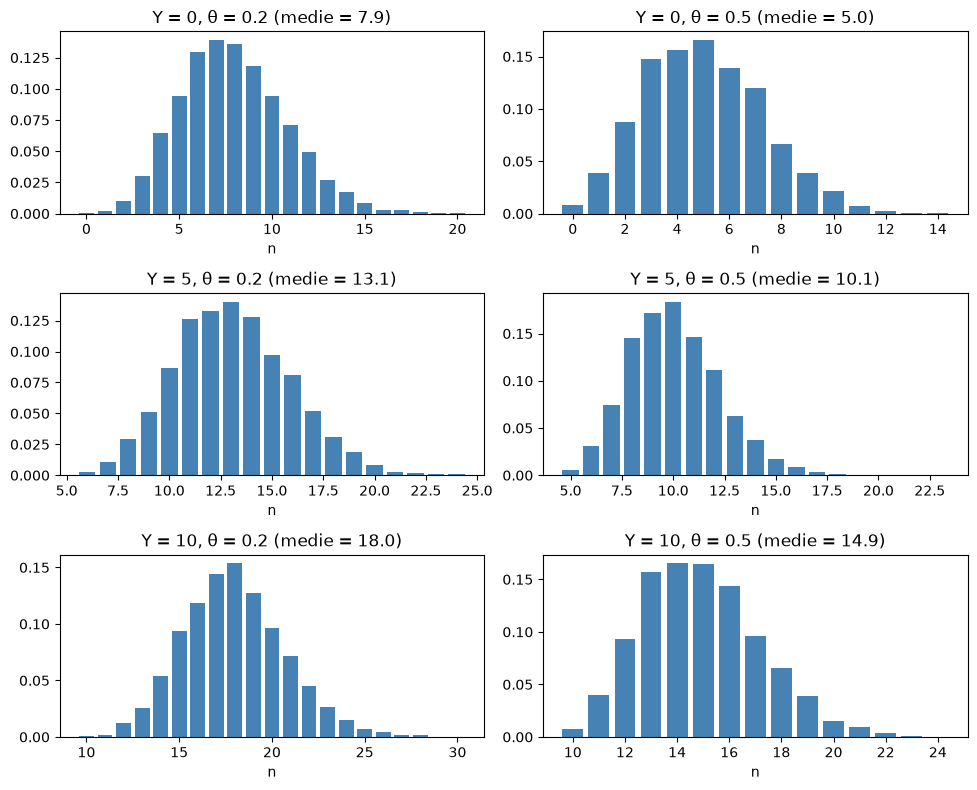

In [9]:
import numpy as np
import pymc as pm
import matplotlib.pyplot as plt

Y_values = [0, 5, 10]
theta_values = [0.2, 0.5]

fig, axes = plt.subplots(3, 2, figsize=(10, 8))

for i, y in enumerate(Y_values):
    for j, theta in enumerate(theta_values):
        with pm.Model():
            n = pm.Poisson("n", mu=10, initval=max(10, y))
            pm.Binomial("Y", n=n, p=theta, observed=y)
            idata = pm.sample(2000, progressbar=False)

        samples = idata.posterior["n"].values.flatten()
        vals, counts = np.unique(samples, return_counts=True)

        ax = axes[i, j]
        ax.bar(vals, counts / counts.sum(), color="steelblue")
        ax.set_title(f"Y = {y}, θ = {theta} (medie = {samples.mean():.1f})")
        ax.set_xlabel("n")

plt.tight_layout()
plt.show()